In [1]:
import pandas as pd
import alphalens as al

factor_df = pd.read_csv("../factor_data_files/factor_data_alpha191_1_long.csv").rename(columns={"instrument":"asset"})
factor_df['date'] = pd.to_datetime(factor_df['date'])
factor_df = factor_df.set_index(['date','asset'])
factor_df

d:\programs\anaconda3\envs\quant-env\Lib\site-packages\requests\__init__.py:86: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


factor
date       asset              
2024-01-02 000001.SZ -0.348907
           000002.SZ -0.381232
           000004.SZ -0.192947
           000005.SZ  0.172429
           000006.SZ -0.490603
...                        ...
2024-08-30 873726.BJ  0.077282
           873806.BJ  0.745666
           873833.BJ -0.267343
           920002.BJ -0.048871
           920118.BJ -0.771506

[865805 rows x 1 columns]

In [2]:
import dolphindb as ddb

s = ddb.session()
s.connect(
    host='10.176.55.211',
    port=8848,
    userid='jiangyushi',
    password='123456'
)

sql = '''
db = database("dfs://YesLab")
stock_daily = loadTable(db, "stock_factor_daily")

SELECT ts_code, trade_date, open
FROM stock_daily
WHERE trade_date BETWEEN date(`2024.01.02) AND date(`2024.08.30);
'''

price_df = s.run(sql).rename(columns={"trade_date":"date", "ts_code":"asset"})
price_df['date'] = pd.to_datetime(price_df['date'])
price_df = price_df.pivot(index='date', columns='asset', values='open')
price_df = price_df.shift(-1).dropna(how='all')
price_df

asset,000001.SZ,000002.SZ,000004.SZ,000005.SZ,000006.SZ,000007.SZ,000008.SZ,000009.SZ,000010.SZ,000011.SZ,...,873679.BJ,873690.BJ,873693.BJ,873703.BJ,873706.BJ,873726.BJ,873806.BJ,873833.BJ,920002.BJ,920118.BJ
date,,,,,,,,,,,,,,,,,,,,,
2024-01-02,9.19,10.15,16.13,1.17,4.46,4.84,2.37,11.66,3.22,8.82,...,24.48,NaN,42.68,39.59,NaN,44.00,NaN,15.60,NaN,NaN
2024-01-03,9.19,10.10,16.19,1.13,4.50,4.94,2.36,11.62,3.15,8.88,...,24.20,NaN,44.50,38.83,NaN,48.00,NaN,15.34,NaN,NaN
2024-01-04,9.10,9.92,16.58,1.16,4.48,4.96,2.36,11.65,3.10,8.92,...,24.89,20.50,44.67,38.84,NaN,46.00,NaN,15.54,NaN,NaN
2024-01-05,9.23,10.03,16.25,1.09,4.66,4.90,2.33,11.74,3.07,9.56,...,24.00,20.31,42.47,40.70,NaN,43.54,NaN,14.69,NaN,NaN
2024-01-08,9.16,9.83,16.15,1.06,4.47,4.75,2.32,11.50,3.10,8.83,...,22.56,20.50,38.86,39.90,NaN,41.90,NaN,14.25,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-08-23,10.50,6.41,11.57,NaN,3.88,4.17,1.98,7.41,1.65,7.32,...,11.16,10.91,21.21,15.82,8.44,14.83,7.68,7.48,44.60,20.12
2024-08-26,10.47,6.50,11.51,NaN,3.89,4.31,2.00,7.60,1.71,7.44,...,11.20,10.72,20.80,15.82,8.36,15.20,7.70,7.47,44.70,19.23
2024-08-27,10.41,6.29,11.42,NaN,3.77,4.48,1.95,7.43,1.69,7.29,...,11.09,10.57,20.18,16.24,8.22,15.06,7.33,7.38,42.88,18.00


In [3]:
# 这里由于pivot，自动补齐了中间缺失日期为NAN，导致结果会多部分0
# 而项目方式选择，直接相邻两天之比，会与其不同

result_df = al.utils.get_clean_factor_and_forward_returns(factor_df, price_df, periods=(1,), quantiles=10)
result_df

Dropped 1.3% entries from factor data: 1.3% in forward returns computation and 0.0% in binning phase (set max_loss=0 to see potentially suppressed Exceptions).
max_loss is 35.0%, not exceeded: OK!


1D    factor  factor_quantile
date       asset                                         
2024-01-02 000001.SZ  0.000000 -0.348907                5
           000002.SZ -0.004926 -0.381232                5
           000004.SZ  0.003720 -0.192947                6
           000005.SZ -0.034188  0.172429                8
           000006.SZ  0.008969 -0.490603                4
...                        ...       ...              ...
2024-08-28 873726.BJ  0.011251  0.267861                7
           873806.BJ  0.005457 -0.363055                3
           873833.BJ -0.002717 -0.128584                5
           920002.BJ  0.009919 -0.467751                3
           920118.BJ -0.007671 -0.756070                1

[854213 rows x 3 columns]

Quantiles Statistics


,min,max,mean,std,count,count %
factor_quantile,,,,,,
1,-1.000000,-0.553141,-0.860217,0.076278,85486,10.007574
2,-0.880823,-0.325374,-0.692463,0.094123,85414,9.999145
3,-0.800429,-0.125586,-0.550490,0.117523,85402,9.997741
4,-0.709366,0.034574,-0.413636,0.135640,85407,9.998326
5,-0.619284,0.191322,-0.275346,0.149427,85437,10.001838
6,-0.512432,0.330849,-0.131935,0.158409,85383,9.995516
7,-0.401567,0.469334,0.020889,0.162772,85383,9.995516
8,-0.268647,0.599548,0.193183,0.160538,85426,10.000550
9,-0.071738,0.758278,0.397597,0.150447,85396,9.997038


Returns Analysis


,1D
Ann. alpha,0.116
beta,0.034
Mean Period Wise Return Top Quantile (bps),3.944
Mean Period Wise Return Bottom Quantile (bps),-6.688
Mean Period Wise Spread (bps),10.632


<Figure size 640x480 with 0 Axes>

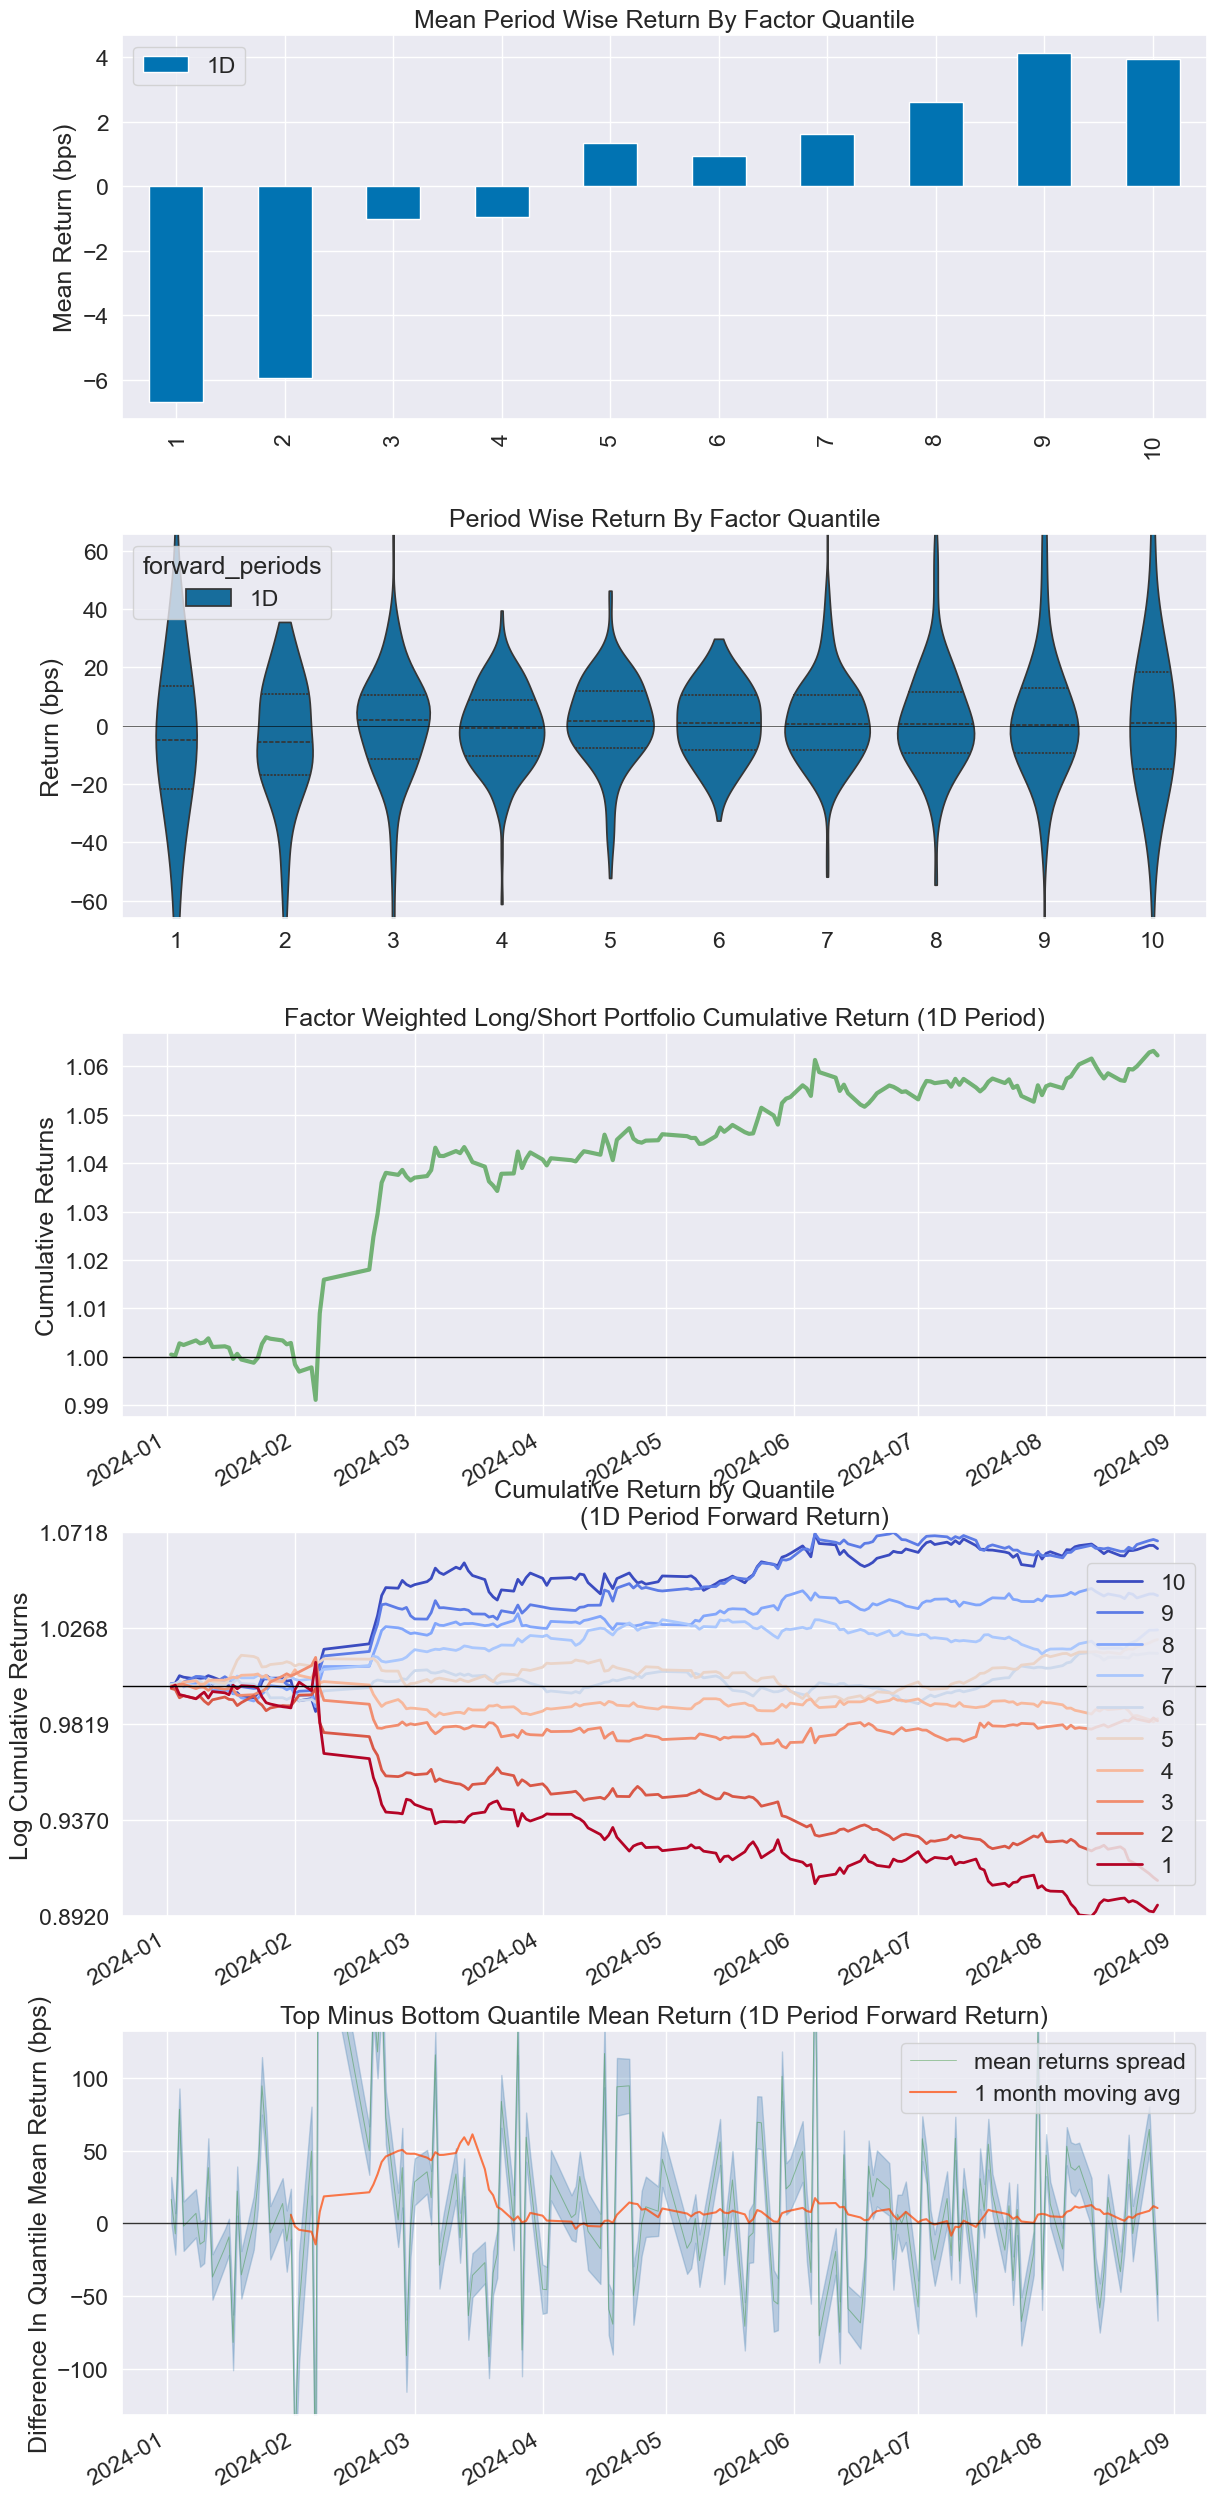

Information Analysis


,1D
IC Mean,0.025
IC Std.,0.068
Risk-Adjusted IC,0.372
t-stat(IC),4.701
p-value(IC),0.000
IC Skew,0.710
IC Kurtosis,0.921


d:\programs\anaconda3\envs\quant-env\Lib\site-packages\alphalens\performance.py:118: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  grouper.append(pd.Grouper(freq=by_time))


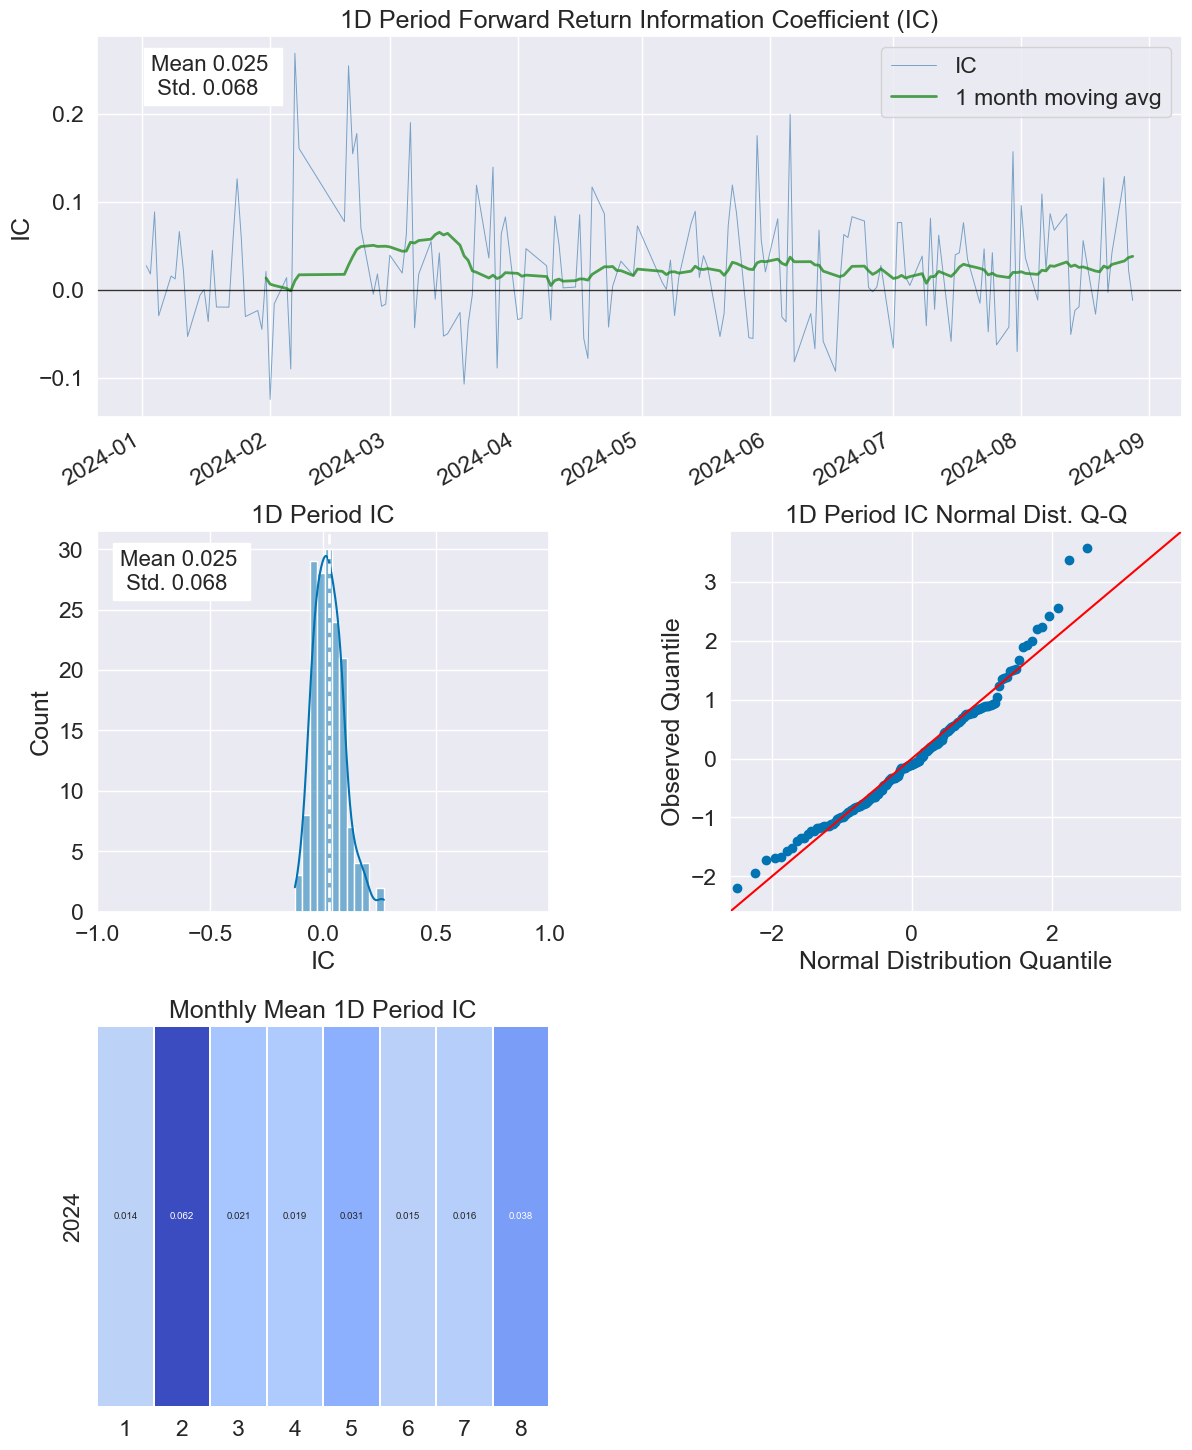

d:\programs\anaconda3\envs\quant-env\Lib\site-packages\alphalens\utils.py:928: UserWarning: Skipping return periods that aren't exact multiples of days.
  warnings.warn(


Turnover Analysis


,1D
Quantile 1 Mean Turnover,0.400
Quantile 2 Mean Turnover,0.647
Quantile 3 Mean Turnover,0.726
Quantile 4 Mean Turnover,0.763
Quantile 5 Mean Turnover,0.779
Quantile 6 Mean Turnover,0.780
Quantile 7 Mean Turnover,0.768
Quantile 8 Mean Turnover,0.736
Quantile 9 Mean Turnover,0.659
Quantile 10 Mean Turnover,0.400


,1D
Mean Factor Rank Autocorrelation,0.815


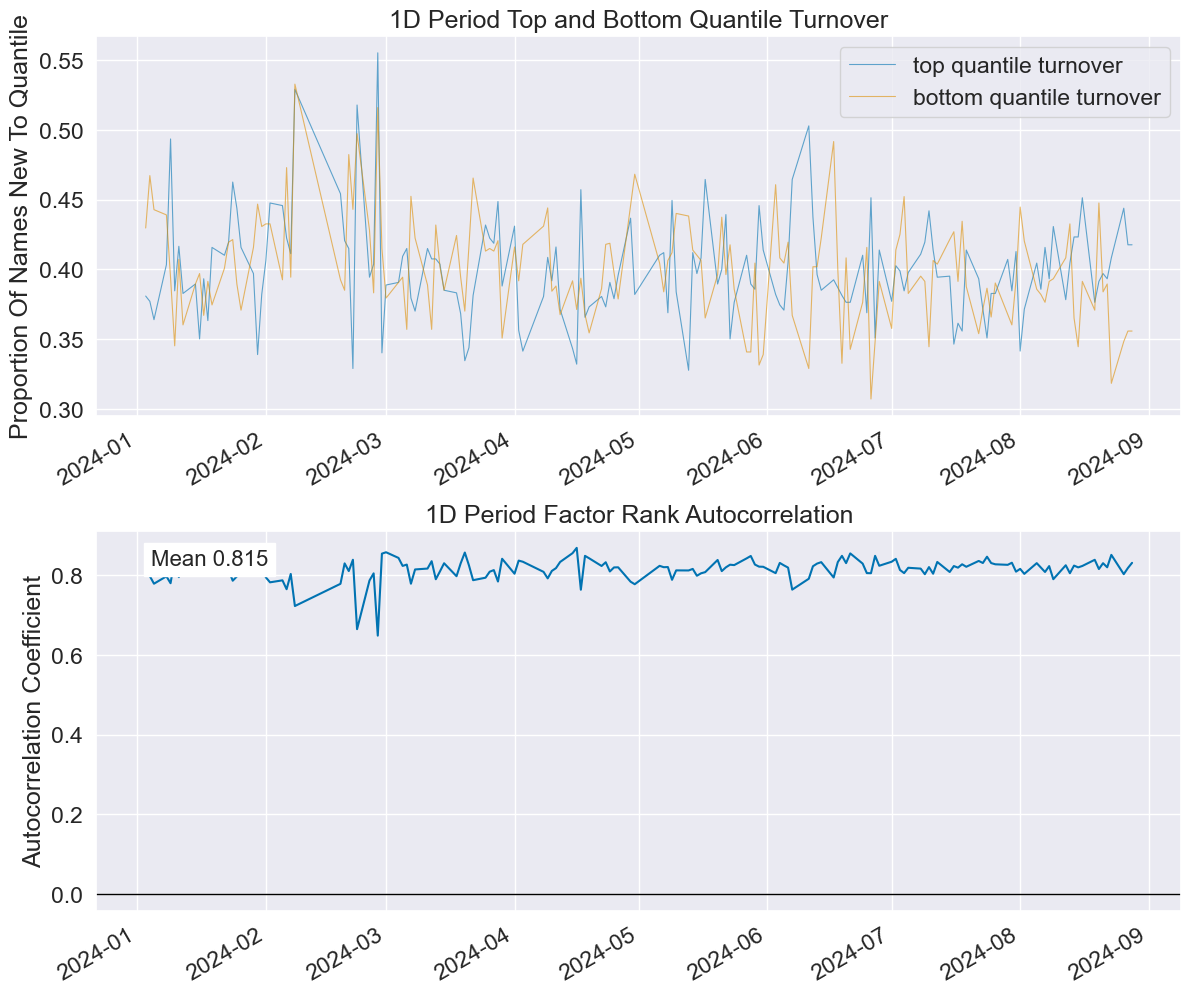

In [4]:
al.tears.create_full_tear_sheet(result_df)